# 04.6 · Feature engineering: dates, ratios, bins, RFM

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/06-feature-engineering/lesson.ipynb)

Read the [README](README.md) first and do the 10-row RFM table on paper. This notebook repeats it in code, then builds the same features for 3,317 real customers and measures whether they help the churn model.

## 1. Ten transactions, three customers

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

tx = pd.DataFrame({
    "customer": list("AAAABBCCCC"),
    "date": pd.to_datetime(["2011-08-25", "2011-08-10", "2011-07-02", "2011-05-15", "2011-06-20",
                            "2011-03-11", "2011-03-01", "2011-02-14", "2011-01-20", "2010-12-12"]),
    "amount": [40, 60, 50, 30, 300, 200, 20, 25, 15, 40],
})
cutoff = pd.Timestamp("2011-09-01")
tx

,customer,date,amount
0,A,2011-08-25,40
1,A,2011-08-10,60
2,A,2011-07-02,50
3,A,2011-05-15,30
4,B,2011-06-20,300
5,B,2011-03-11,200
6,C,2011-03-01,20
7,C,2011-02-14,25
8,C,2011-01-20,15
9,C,2010-12-12,40


## 2. Date features

A raw timestamp means nothing to a model. Pandas' `.dt` accessor pulls out the parts that might matter.

In [2]:
tx["day_of_week"] = tx["date"].dt.day_name()
tx["month"] = tx["date"].dt.month
tx["days_before_cutoff"] = (cutoff - tx["date"]).dt.days
tx

,customer,date,amount,day_of_week,month,days_before_cutoff
0,A,2011-08-25,40,Thursday,8,7
1,A,2011-08-10,60,Wednesday,8,22
2,A,2011-07-02,50,Saturday,7,61
3,A,2011-05-15,30,Sunday,5,109
4,B,2011-06-20,300,Monday,6,73
5,B,2011-03-11,200,Friday,3,174
6,C,2011-03-01,20,Tuesday,3,184
7,C,2011-02-14,25,Monday,2,199
8,C,2011-01-20,15,Thursday,1,224
9,C,2010-12-12,40,Sunday,12,263


## 3. RFM by hand, in code

One row per customer. Compare with your paper table: A should be R = 7, F = 4, M = 180.

In [3]:
rfm = tx.groupby("customer").agg(last=("date", "max"), first=("date", "min"),
                                 F=("date", "count"), M=("amount", "sum"))
rfm["R"] = (cutoff - rfm["last"]).dt.days          # recency: days since last order
rfm["tenure"] = (cutoff - rfm["first"]).dt.days    # days since first order
rfm["avg_basket"] = rfm["M"] / rfm["F"]            # ratio: £ per order
rfm["log_M"] = np.log1p(rfm["M"]).round(3)         # log(1 + M)
rfm[["R", "F", "M", "tenure", "avg_basket", "log_M"]]

,R,F,M,tenure,avg_basket,log_M
customer,,,,,,
A,7,4,180,109,45.0,5.198
B,73,2,500,174,250.0,6.217
C,184,4,100,263,25.0,4.615


Three customers, three stories the raw rows did not tell:

- **A** ordered a week ago, four times, small baskets: a regular.
- **B** spends big but rarely and has gone quiet for 73 days.
- **C** has not ordered for six months: very likely gone.

## 4. The real customer table

Same table as Modules 01.9 and 03 (cut-off 2011-09-01). Loading takes about a second thanks to the Parquet cache.

In [4]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")                       # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])
features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

3,317 customers, churn rate 43.6%


## 5. Is `spend` skewed? Look before you transform

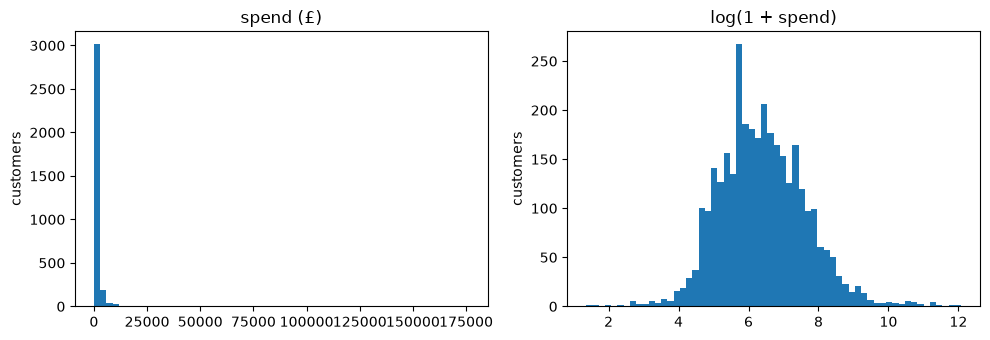

skew before: 16.3   after log: 0.39


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
cust["spend"].plot.hist(bins=60, ax=axes[0], title="spend (£)")
np.log1p(cust["spend"]).plot.hist(bins=60, ax=axes[1], title="log(1 + spend)")
for ax in axes: ax.set_ylabel("customers")
plt.tight_layout(); plt.show()
print(f"skew before: {cust['spend'].skew():.1f}   after log: {np.log1p(cust['spend']).skew():.2f}")

Left: almost everyone squashed against zero, a few whales stretching the axis to £176,000. Right: a readable hump. A linear model sees the right-hand version much more fairly.

## 6. Engineer the features

Ratios, logs, a country flag, a weekend share and a "recent activity" count. Each line is one idea from the README.

In [6]:
cust["avg_basket"] = cust["spend"] / cust["orders"]
cust["orders_per_month"] = cust["orders"] / (cust["tenure_days"] / 30).clip(lower=1)
cust["log_spend"] = np.log1p(cust["spend"])
country = past.groupby("Customer ID")["Country"].agg(lambda s: s.mode()[0])
cust["country"] = country.reindex(cust.index)
cust["is_uk"] = (cust["country"] == "United Kingdom").astype(int)
weekend = past.assign(wk=past["InvoiceDate"].dt.dayofweek >= 5).groupby("Customer ID")["wk"].mean()
cust["share_weekend"] = weekend.reindex(cust.index)
autumn = past[past["InvoiceDate"] >= "2011-06-01"].groupby("Customer ID")["Invoice"].nunique()
cust["orders_last_3m"] = autumn.reindex(cust.index).fillna(0)

for col in ["orders", "products", "days_since_last", "avg_basket", "orders_last_3m"]:
    cust["log_" + col] = np.log1p(cust[col])
cust.head()

,orders,spend,products,tenure_days,days_since_last,churned,avg_basket,orders_per_month,log_spend,country,is_uk,share_weekend,orders_last_3m,log_orders,log_products,log_days_since_last,log_avg_basket,log_orders_last_3m
Customer ID,,,,,,,,,,,,,,,,,,
12346.0,1,77183.60,1,225,225,1,77183.600000,0.133333,11.253955,United Kingdom,1,0.0,0.0,0.693147,0.693147,5.420535,11.253955,0.000000
12347.0,5,2790.86,82,267,29,0,558.172000,0.561798,7.934463,Iceland,0,0.0,2.0,1.791759,4.418841,3.401197,6.326457,1.098612
12348.0,3,1487.24,22,258,148,0,495.746667,0.348837,7.305349,Finland,0,0.0,0.0,1.386294,3.135494,5.003946,6.208080,0.000000
12350.0,1,334.40,17,210,210,1,334.400000,0.142857,5.815324,Norway,0,0.0,0.0,0.693147,2.890372,5.351858,5.815324,0.000000
12352.0,5,1561.81,26,196,162,0,312.362000,0.765306,7.354241,Norway,0,0.0,0.0,1.791759,3.295837,5.093750,5.747359,0.000000


## 7. Bins: churn rate by recency band

Binning turns a number into ordered groups. It is also the quickest way to *see* a relationship.

In [7]:
cust["recency_band"] = pd.cut(cust["days_since_last"], bins=[-1, 30, 90, 180, 400],
                              labels=["0-30 d", "31-90 d", "91-180 d", "181+ d"])
cust.groupby("recency_band", observed=True)["churned"].agg(["count", "mean"]).round(3)

,count,mean
recency_band,,
0-30 d,935,0.250
31-90 d,999,0.380
91-180 d,850,0.562
181+ d,533,0.664


Churn climbs steadily from 25% (ordered in the last month) to 66% (silent for six months or more). Recency matters, and roughly in a straight line across bands.

## 8. Do the features help the model?

We score scaled logistic regression on the same held-out 25% of customers with different feature sets. The first line reproduces Module 03's AUC of 0.741.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

train, test = train_test_split(cust, test_size=0.25, random_state=42, stratify=cust["churned"])

def test_auc(cols):
    """Fit scaled logistic regression on train, return AUC on test."""
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    model.fit(train[cols], train["churned"])
    return roc_auc_score(test["churned"], model.predict_proba(test[cols])[:, 1])

In [9]:
raw_5 = ["orders", "spend", "products", "tenure_days", "days_since_last"]
logged = ["log_orders", "log_spend", "log_products", "tenure_days", "log_days_since_last"]
sets = {
    "raw 5 features (Module 03)": raw_5,
    "same 5, skewed ones logged": logged,
    "+ ratios (avg basket, orders/month)": logged + ["log_avg_basket", "orders_per_month"],
    "+ recent activity": logged + ["log_avg_basket", "orders_per_month", "log_orders_last_3m"],
    "+ country & weekend": logged + ["log_avg_basket", "orders_per_month", "log_orders_last_3m",
                                     "is_uk", "share_weekend"],
}
for name, cols in sets.items():
    print(f"{name:<38} AUC {test_auc(cols):.3f}")

raw 5 features (Module 03)             AUC 0.741
same 5, skewed ones logged             AUC 0.747
+ ratios (avg basket, orders/month)    AUC 0.747
+ recent activity                      AUC 0.742
+ country & weekend                    AUC 0.742


Read this honestly:

- **Logging the skewed columns helped**, from 0.741 to 0.747. Same information, presented in a shape a linear model can use.
- **More features did not keep helping.** Ratios added nothing; recent activity, country and weekend share slightly *lowered* the score. Each new column is also a new chance to fit noise.
- **The differences are tiny.** 0.006 of AUC on 830 test customers could be luck. Lesson 04.7 (cross-validation) gives you a way to tell a real gain from a lucky split.

## 9. A transform that changes nothing on its own

Logging does not change the *order* of values, so a single-feature AUC (which only cares about ranking) cannot move:

In [10]:
for col in ["spend", "days_since_last"]:
    print(f"{col:<16} AUC {test_auc([col]):.3f}    log({col}) AUC {test_auc(['log_' + col]):.3f}")

spend            AUC 0.727    log(spend) AUC 0.727
days_since_last  AUC 0.675    log(days_since_last) AUC 0.675


Identical. The log helped in section 8 because, with several features combined linearly, the *shape* of each one matters. Trees (Module 05) only use the order of values, so they barely care about logs at all.

## Quiz answers

1. Recency = days from the last order to the cut-off. For C: 2011-03-01 to 2011-09-01 = 184 days.
2. Because a raw date is just a growing number. The model cannot know that "Friday" or "December" or "60 days ago" is what matters unless you compute it.
3. `log1p(x) = ln(1 + x)`. It works when x = 0 (gives 0), where plain `log` would give minus infinity.
4. Any one of: features must be computed only from data before the cut-off (no peeking at the future); a ratio with a zero denominator; more features means more ways to overfit; the gain may be smaller than the noise in one test split.
5. Trees split on thresholds, so only the order of values matters, and a log keeps the order. Linear models and KNN use the actual distances between values, so the shape matters.

**Next:** [04.7 Cross-validation](../07-cross-validation/)